## PRS Weight Comparison

This notebook compares the final PRS weight files generated by the four ancestry configurations:

AFR GWAS + AFR LD
AFR GWAS + EUR LD
EUR GWAS + AFR LD
EUR GWAS + EUR LD

The purpose is to determine whether discovery-GWAS ancestry and LD-reference ancestry influence the composition of the final weighted variant set after LD clumping.

PRS_LD_compariosn established that LD-reference ancestry changes the number, and identity of index SNPs. We'll extend this analysis by examining the GWAS-derived quantities attached to those retained variants, including BETA, SE, P, EAF and sample size.

The LD reference does not modify the GWAS effect estimate itself. Differences in the distributions of BETA, EAF or P therefore reflect differences in the variants retained by the clumping procedure, rather than changes to the underlying GWAS estimates.

## How does the composition of the final weighted variant set differ?

## Mount Google Drive

Google Drive is mounted to provide persistent storage for the project files and intermediate results.

Using persistent storage prevents the loss of large reference datasets and computational outputs when the Colab runtime is disconnected or restarted.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


## Imports and project paths

In [ ]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Four completed PRS pipelines

PROJECT_AFR_AFR = Path(
    "/content/drive/MyDrive/PRS_T2D"
)

PROJECT_AFR_EUR = Path(
    "/content/drive/MyDrive/PRS_T2D_A-E"
)

PROJECT_EUR_AFR = Path(
    "/content/drive/MyDrive/PRS_T2D_E-A"
)

PROJECT_EUR_EUR = Path(
    "/content/drive/MyDrive/PRS_T2D_E-E"
)


# P-value thresholds

THRESHOLDS = {
    "P5e-08": 5e-8,
    "P1e-05": 1e-5,
    "P0.0001": 1e-4,
    "P0.001": 1e-3,
    "P0.01": 1e-2,
    "P0.05": 5e-2
}


CHROMOSOMES = list(range(1, 23))

print("Projects, thresholds and chromosomes defined.")

Projects, thresholds and chromosomes defined.


## Define weight directories

In [ ]:
WEIGHT_DIRS = {
    "AFR-AFR": (
        PROJECT_AFR_AFR
        / "results"
        / "weights"
    ),

    "AFR-EUR": (
        PROJECT_AFR_EUR
        / "results"
        / "weights"
    ),

    "EUR-AFR": (
        PROJECT_EUR_AFR
        / "results"
        / "weights"
    ),

    "EUR-EUR": (
        PROJECT_EUR_EUR
        / "results"
        / "weights"
    )
}


for pipeline, path in WEIGHT_DIRS.items():
    print(f"{pipeline}: {path}")

AFR-AFR: /content/drive/MyDrive/PRS_T2D/results/weights
AFR-EUR: /content/drive/MyDrive/PRS_T2D_A-E/results/weights
EUR-AFR: /content/drive/MyDrive/PRS_T2D_E-A/results/weights
EUR-EUR: /content/drive/MyDrive/PRS_T2D_E-E/results/weights


## Define exact weight filenames

In [ ]:
WEIGHT_FILENAMES = {
    "AFR-AFR": {t: "MVP_T2D_AFR_weights.tsv" for t in THRESHOLDS},
    "AFR-EUR": {t: "T2D_PheCode250_2_AFR_weights.tsv" for t in THRESHOLDS},
    "EUR-AFR": {t: "MVP_T2D_EUR_weights_FIXED.tsv" for t in THRESHOLDS},
    "EUR-EUR": {t: "MVP_T2D_EUR_weights_FIXED.tsv" for t in THRESHOLDS},
}
WEIGHT_FILENAMES

{'AFR-AFR': {'P5e-08': 'MVP_T2D_AFR_weights.tsv',
  'P1e-05': 'MVP_T2D_AFR_weights.tsv',
  'P0.0001': 'MVP_T2D_AFR_weights.tsv',
  'P0.001': 'MVP_T2D_AFR_weights.tsv',
  'P0.01': 'MVP_T2D_AFR_weights.tsv',
  'P0.05': 'MVP_T2D_AFR_weights.tsv'},
 'AFR-EUR': {'P5e-08': 'T2D_PheCode250_2_AFR_weights.tsv',
  'P1e-05': 'T2D_PheCode250_2_AFR_weights.tsv',
  'P0.0001': 'T2D_PheCode250_2_AFR_weights.tsv',
  'P0.001': 'T2D_PheCode250_2_AFR_weights.tsv',
  'P0.01': 'T2D_PheCode250_2_AFR_weights.tsv',
  'P0.05': 'T2D_PheCode250_2_AFR_weights.tsv'},
 'EUR-AFR': {'P5e-08': 'MVP_T2D_EUR_weights_FIXED.tsv',
  'P1e-05': 'MVP_T2D_EUR_weights_FIXED.tsv',
  'P0.0001': 'MVP_T2D_EUR_weights_FIXED.tsv',
  'P0.001': 'MVP_T2D_EUR_weights_FIXED.tsv',
  'P0.01': 'MVP_T2D_EUR_weights_FIXED.tsv',
  'P0.05': 'MVP_T2D_EUR_weights_FIXED.tsv'},
 'EUR-EUR': {'P5e-08': 'MVP_T2D_EUR_weights_FIXED.tsv',
  'P1e-05': 'MVP_T2D_EUR_weights_FIXED.tsv',
  'P0.0001': 'MVP_T2D_EUR_weights_FIXED.tsv',
  'P0.001': 'MVP_T2D_EUR_wei

## Verify all 24 weight files

In [ ]:
weight_inventory = []

for pipeline, base_dir in WEIGHT_DIRS.items():

    for threshold in THRESHOLDS:

        weight_file = (
            base_dir
            / threshold
            / WEIGHT_FILENAMES[pipeline][threshold]
        )

        weight_inventory.append({
            "Pipeline": pipeline,
            "Threshold": threshold,
            "Path": weight_file,
            "Exists": weight_file.exists()
        })


weight_inventory = pd.DataFrame(weight_inventory)

print(
    "Total expected weight files:",
    len(weight_inventory)
)

print(
    "Files present:",
    weight_inventory["Exists"].sum()
)

print(
    "Files missing:",
    (~weight_inventory["Exists"]).sum()
)

display(weight_inventory)

Total expected weight files: 24
Files present: 24
Files missing: 0


,Pipeline,Threshold,Path,Exists
0,AFR-AFR,P5e-08,/content/drive/MyDrive/PRS_T2D/results/weights...,True
1,AFR-AFR,P1e-05,/content/drive/MyDrive/PRS_T2D/results/weights...,True
2,AFR-AFR,P0.0001,/content/drive/MyDrive/PRS_T2D/results/weights...,True
3,AFR-AFR,P0.001,/content/drive/MyDrive/PRS_T2D/results/weights...,True
4,AFR-AFR,P0.01,/content/drive/MyDrive/PRS_T2D/results/weights...,True
5,AFR-AFR,P0.05,/content/drive/MyDrive/PRS_T2D/results/weights...,True
6,AFR-EUR,P5e-08,/content/drive/MyDrive/PRS_T2D_A-E/results/wei...,True
7,AFR-EUR,P1e-05,/content/drive/MyDrive/PRS_T2D_A-E/results/wei...,True
8,AFR-EUR,P0.0001,/content/drive/MyDrive/PRS_T2D_A-E/results/wei...,True
9,AFR-EUR,P0.001,/content/drive/MyDrive/PRS_T2D_A-E/results/wei...,True


## Load all weight files

In [ ]:
weight_data = {}

for pipeline, base_dir in WEIGHT_DIRS.items():

    weight_data[pipeline] = {}

    for threshold in THRESHOLDS:

        weight_file = (
            base_dir
            / threshold
            / WEIGHT_FILENAMES[pipeline][threshold]
        )

        df = pd.read_csv(
            weight_file,
            sep="\t"
        )

        df["SNP"] = (
            df["SNP"]
            .astype(str)
            .str.strip()
        )

        weight_data[pipeline][threshold] = df


print("All 24 PRS weight files loaded.")

All 24 PRS weight files loaded.


## Verify required columns

In [ ]:
REQUIRED_WEIGHT_COLUMNS = [
    "SNP",
    "CHR",
    "BP",
    "A1",
    "A2",
    "EAF",
    "BETA",
    "SE",
    "P",
    "N"
]


weight_column_check = []

for pipeline in weight_data:

    for threshold in THRESHOLDS:

        df = weight_data[pipeline][threshold]

        missing_columns = [
            column
            for column in REQUIRED_WEIGHT_COLUMNS
            if column not in df.columns
        ]

        weight_column_check.append({
            "Pipeline": pipeline,
            "Threshold": threshold,
            "Missing_Columns": ", ".join(missing_columns),
            "Columns_OK": len(missing_columns) == 0
        })


weight_column_check = pd.DataFrame(weight_column_check)

display(weight_column_check)

print(
    "All column checks passed:",
    weight_column_check["Columns_OK"].all()
)

,Pipeline,Threshold,Missing_Columns,Columns_OK
0,AFR-AFR,P5e-08,,True
1,AFR-AFR,P1e-05,,True
2,AFR-AFR,P0.0001,,True
3,AFR-AFR,P0.001,,True
4,AFR-AFR,P0.01,,True
5,AFR-AFR,P0.05,,True
6,AFR-EUR,P5e-08,,True
7,AFR-EUR,P1e-05,,True
8,AFR-EUR,P0.0001,,True
9,AFR-EUR,P0.001,,True


All column checks passed: True


## Check duplicate SNPs

In [ ]:
weight_duplicate_records = []

for pipeline in weight_data:

    for threshold in THRESHOLDS:

        df = weight_data[pipeline][threshold]

        duplicate_count = (
            df["SNP"]
            .duplicated()
            .sum()
        )

        weight_duplicate_records.append({
            "Pipeline": pipeline,
            "Threshold": threshold,
            "Duplicate_SNPs": duplicate_count,
            "Unique_SNPs": df["SNP"].nunique(),
            "Rows": len(df)
        })


weight_duplicate_check = pd.DataFrame(
    weight_duplicate_records
)

display(weight_duplicate_check)

,Pipeline,Threshold,Duplicate_SNPs,Unique_SNPs,Rows
0,AFR-AFR,P5e-08,0,1710,1710
1,AFR-AFR,P1e-05,0,4305,4305
2,AFR-AFR,P0.0001,0,7666,7666
3,AFR-AFR,P0.001,0,19691,19691
4,AFR-AFR,P0.01,0,90187,90187
5,AFR-AFR,P0.05,0,357804,357804
6,AFR-EUR,P5e-08,0,633,633
7,AFR-EUR,P1e-05,0,1636,1636
8,AFR-EUR,P0.0001,0,3302,3302
9,AFR-EUR,P0.001,0,11288,11288


## Count final weighted variants

In [ ]:
weight_counts_records = []

for pipeline in weight_data:

    for threshold in THRESHOLDS:

        df = weight_data[pipeline][threshold]

        weight_counts_records.append({
            "Pipeline": pipeline,
            "Threshold": threshold,
            "P_threshold": THRESHOLDS[threshold],
            "Weighted_SNPs": df["SNP"].nunique()
        })


weight_counts = pd.DataFrame(
    weight_counts_records
)

display(weight_counts)

,Pipeline,Threshold,P_threshold,Weighted_SNPs
0,AFR-AFR,P5e-08,5.000000e-08,1710
1,AFR-AFR,P1e-05,1.000000e-05,4305
2,AFR-AFR,P0.0001,1.000000e-04,7666
3,AFR-AFR,P0.001,1.000000e-03,19691
4,AFR-AFR,P0.01,1.000000e-02,90187
5,AFR-AFR,P0.05,5.000000e-02,357804
6,AFR-EUR,P5e-08,5.000000e-08,633
7,AFR-EUR,P1e-05,1.000000e-05,1636
8,AFR-EUR,P0.0001,1.000000e-04,3302
9,AFR-EUR,P0.001,1.000000e-03,11288


## Compare index counts with weights

In [ ]:
LD_COMPARISON_DIR = Path(
    "/content/drive/MyDrive/"
    "PRS_T2D_comparison/"
    "PRS_LD_Clumping_Comparison"
)

LD_SUMMARY_FILE = (
    LD_COMPARISON_DIR
    / "LD_clumping_summary.tsv"
)

index_reference = pd.read_csv(
    LD_SUMMARY_FILE,
    sep="\t"
)

index_reference = index_reference[
    [
        "Pipeline",
        "Threshold",
        "P_threshold",
        "Index_SNPs"
    ]
]

index_weight_check = index_reference.merge(
    weight_counts,
    on=[
        "Pipeline",
        "Threshold",
        "P_threshold"
    ],
    how="outer"
)

index_weight_check["Count_Match"] = (
    index_weight_check["Index_SNPs"]
    ==
    index_weight_check["Weighted_SNPs"]
)

display(index_weight_check)

,Pipeline,Threshold,P_threshold,Index_SNPs,Weighted_SNPs,Count_Match
0,AFR-AFR,P0.0001,1.000000e-04,7666,7666,True
1,AFR-AFR,P0.001,1.000000e-03,19691,19691,True
2,AFR-AFR,P0.01,1.000000e-02,90187,90187,True
3,AFR-AFR,P0.05,5.000000e-02,357804,357804,True
4,AFR-AFR,P1e-05,1.000000e-05,4305,4305,True
5,AFR-AFR,P5e-08,5.000000e-08,1710,1710,True
6,AFR-EUR,P0.0001,1.000000e-04,3302,3302,True
7,AFR-EUR,P0.001,1.000000e-03,11288,11288,True
8,AFR-EUR,P0.01,1.000000e-02,74325,74325,True
9,AFR-EUR,P0.05,5.000000e-02,358128,358128,True


## Create the master weight summary

In [ ]:
weight_summary_records = []

for pipeline in weight_data:

    for threshold in THRESHOLDS:

        df = weight_data[pipeline][threshold]

        weight_summary_records.append({
            "Pipeline": pipeline,
            "GWAS_Ancestry": (
                "AFR"
                if pipeline.startswith("AFR")
                else "EUR"
            ),
            "LD_Ancestry": (
                "AFR"
                if pipeline.endswith("AFR")
                else "EUR"
            ),
            "Threshold": threshold,
            "P_threshold": THRESHOLDS[threshold],
            "Weighted_SNPs": df["SNP"].nunique(),

            "Mean_BETA": df["BETA"].mean(),
            "Median_BETA": df["BETA"].median(),
            "SD_BETA": df["BETA"].std(),

            "Mean_abs_BETA": df["BETA"].abs().mean(),
            "Median_abs_BETA": df["BETA"].abs().median(),

            "Mean_EAF": df["EAF"].mean(),
            "Median_EAF": df["EAF"].median(),

            "Mean_P": df["P"].mean(),
            "Median_P": df["P"].median()
        })


weight_summary = pd.DataFrame(
    weight_summary_records
)

display(weight_summary)

,Pipeline,GWAS_Ancestry,LD_Ancestry,Threshold,P_threshold,Weighted_SNPs,Mean_BETA,Median_BETA,SD_BETA,Mean_abs_BETA,Median_abs_BETA,Mean_EAF,Median_EAF,Mean_P,Median_P
0,AFR-AFR,AFR,AFR,P5e-08,5.000000e-08,1710,-0.001799,-0.008834,0.027408,0.019870,0.013268,0.470350,0.46150,5.460369e-09,7.983500e-11
1,AFR-AFR,AFR,AFR,P1e-05,1.000000e-05,4305,-0.000200,-0.006957,0.030929,0.016892,0.010758,0.458686,0.44000,1.710153e-06,2.588000e-07
2,AFR-AFR,AFR,AFR,P0.0001,1.000000e-04,7666,0.000930,0.005967,0.045375,0.019861,0.010097,0.456120,0.42990,2.124280e-05,5.962000e-06
3,AFR-AFR,AFR,AFR,P0.001,1.000000e-03,19691,0.003683,0.005287,0.087090,0.034967,0.010975,0.442335,0.38680,3.116708e-04,2.034000e-04
4,AFR-AFR,AFR,AFR,P0.01,1.000000e-02,90187,0.006830,0.004635,0.153014,0.067797,0.022005,0.424161,0.24420,4.199509e-03,3.919000e-03
5,AFR-AFR,AFR,AFR,P0.05,5.000000e-02,357804,0.003191,0.003933,0.201717,0.087556,0.032159,0.414671,0.07462,2.330717e-02,2.290000e-02
6,AFR-EUR,AFR,EUR,P5e-08,5.000000e-08,633,-0.000194,-0.008636,0.022838,0.017952,0.013163,0.455143,0.42620,5.838452e-09,2.020000e-10
7,AFR-EUR,AFR,EUR,P1e-05,1.000000e-05,1636,-0.001795,-0.006892,0.105258,0.022264,0.011262,0.443716,0.40715,1.746209e-06,3.051000e-07
8,AFR-EUR,AFR,EUR,P0.0001,1.000000e-04,3302,0.003222,0.006184,0.110086,0.038640,0.011292,0.441013,0.39165,2.507497e-05,1.025000e-05
9,AFR-EUR,AFR,EUR,P0.001,1.000000e-03,11288,0.008789,0.005697,0.148353,0.078009,0.019471,0.431396,0.31705,3.762072e-04,3.212000e-04


## Positive and negative effect composition

In [ ]:
effect_direction_records = []

for pipeline in weight_data:

    for threshold in THRESHOLDS:

        df = weight_data[pipeline][threshold]

        positive = (df["BETA"] > 0).sum()
        negative = (df["BETA"] < 0).sum()
        zero = (df["BETA"] == 0).sum()

        total = len(df)

        effect_direction_records.append({
            "Pipeline": pipeline,
            "Threshold": threshold,
            "Positive_BETA": positive,
            "Negative_BETA": negative,
            "Zero_BETA": zero,
            "Positive_pct": positive / total * 100,
            "Negative_pct": negative / total * 100
        })


effect_direction = pd.DataFrame(
    effect_direction_records
)

display(effect_direction)

,Pipeline,Threshold,Positive_BETA,Negative_BETA,Zero_BETA,Positive_pct,Negative_pct
0,AFR-AFR,P5e-08,802,908,0,46.900585,53.099415
1,AFR-AFR,P1e-05,2115,2190,0,49.128920,50.871080
2,AFR-AFR,P0.0001,3835,3831,0,50.026089,49.973911
3,AFR-AFR,P0.001,10057,9634,0,51.074095,48.925905
4,AFR-AFR,P0.01,47240,42947,0,52.380055,47.619945
5,AFR-AFR,P0.05,185498,172306,0,51.843467,48.156533
6,AFR-EUR,P5e-08,307,326,0,48.499210,51.500790
7,AFR-EUR,P1e-05,813,823,0,49.694377,50.305623
8,AFR-EUR,P0.0001,1676,1626,0,50.757117,49.242883
9,AFR-EUR,P0.001,5917,5371,0,52.418498,47.581502


## Compare weighted-SNP identities

In [ ]:
def compare_weight_sets(df1, df2):

    set1 = set(df1["SNP"])
    set2 = set(df2["SNP"])

    shared = set1 & set2
    only1 = set1 - set2
    only2 = set2 - set1
    union = set1 | set2

    jaccard = (
        len(shared) / len(union)
        if len(union) > 0
        else np.nan
    )

    return {
        "Set1_n": len(set1),
        "Set2_n": len(set2),
        "Shared": len(shared),
        "Set1_only": len(only1),
        "Set2_only": len(only2),
        "Union": len(union),
        "Jaccard": jaccard
    }

### African-GWAS weighted SNP overlap

In [ ]:
afr_weight_overlap_records = []

for threshold in THRESHOLDS:

    afr_afr = weight_data[
        "AFR-AFR"
    ][threshold]

    afr_eur = weight_data[
        "AFR-EUR"
    ][threshold]

    comparison = compare_weight_sets(
        afr_afr,
        afr_eur
    )

    afr_weight_overlap_records.append({
        "Threshold": threshold,
        **comparison
    })


afr_weight_overlap = pd.DataFrame(
    afr_weight_overlap_records
)

display(afr_weight_overlap)

,Threshold,Set1_n,Set2_n,Shared,Set1_only,Set2_only,Union,Jaccard
0,P5e-08,1710,633,511,1199,122,1832,0.278930
1,P1e-05,4305,1636,1337,2968,299,4604,0.290400
2,P0.0001,7666,3302,2656,5010,646,8312,0.319538
3,P0.001,19691,11288,8765,10926,2523,22214,0.394571
4,P0.01,90187,74325,52476,37711,21849,112036,0.468385
5,P0.05,357804,358128,224817,132987,133311,491115,0.457769


### European-GWAS weighted SNP overlap

In [ ]:
eur_weight_overlap_records = []

for threshold in THRESHOLDS:

    eur_afr = weight_data[
        "EUR-AFR"
    ][threshold]

    eur_eur = weight_data[
        "EUR-EUR"
    ][threshold]

    comparison = compare_weight_sets(
        eur_afr,
        eur_eur
    )

    eur_weight_overlap_records.append({
        "Threshold": threshold,
        **comparison
    })


eur_weight_overlap = pd.DataFrame(
    eur_weight_overlap_records
)

display(eur_weight_overlap)

,Threshold,Set1_n,Set2_n,Shared,Set1_only,Set2_only,Union,Jaccard
0,P5e-08,4944,2063,1689,3255,374,5318,0.317601
1,P1e-05,16558,9216,7382,9176,1834,18392,0.401370
2,P0.0001,37511,25465,19286,18225,6179,43690,0.441428
3,P0.001,107335,83925,61112,46223,22813,130148,0.469558
4,P0.01,364262,319256,214974,149288,104282,468544,0.458813
5,P0.05,920240,842495,529536,390704,312959,1233199,0.429400


## BETA distribution plot

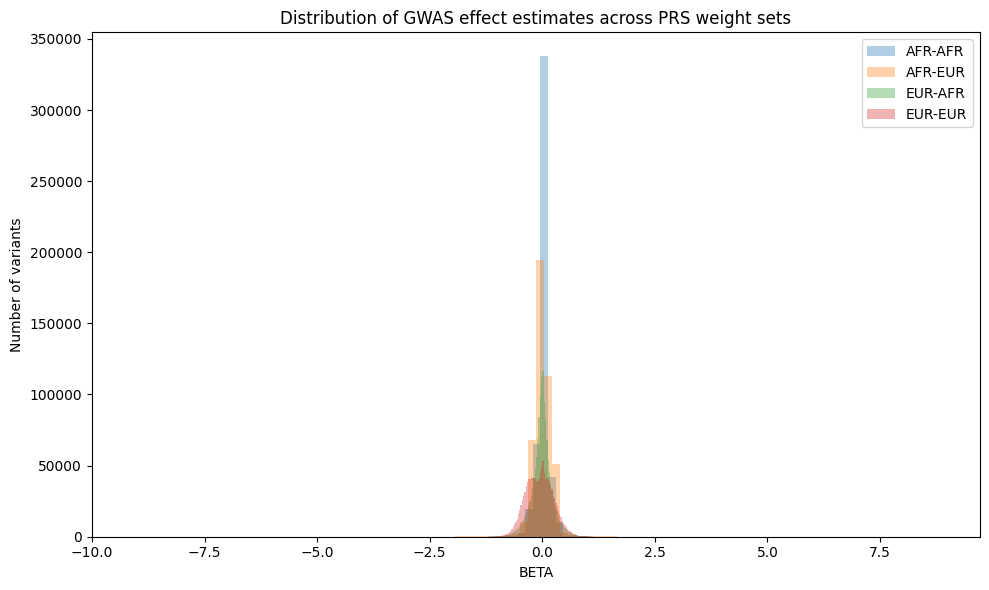

In [ ]:
plt.figure(figsize=(10, 6))

for pipeline in weight_data:

    values = []

    for threshold in THRESHOLDS:
        values.extend(
            weight_data[pipeline][threshold]["BETA"]
        )

    plt.hist(
        values,
        bins=100,
        alpha=0.35,
        label=pipeline
    )

plt.xlabel("BETA")
plt.ylabel("Number of variants")
plt.title("Distribution of GWAS effect estimates across PRS weight sets")
plt.legend()
plt.tight_layout()
plt.show()

## Absolute BETA comparison

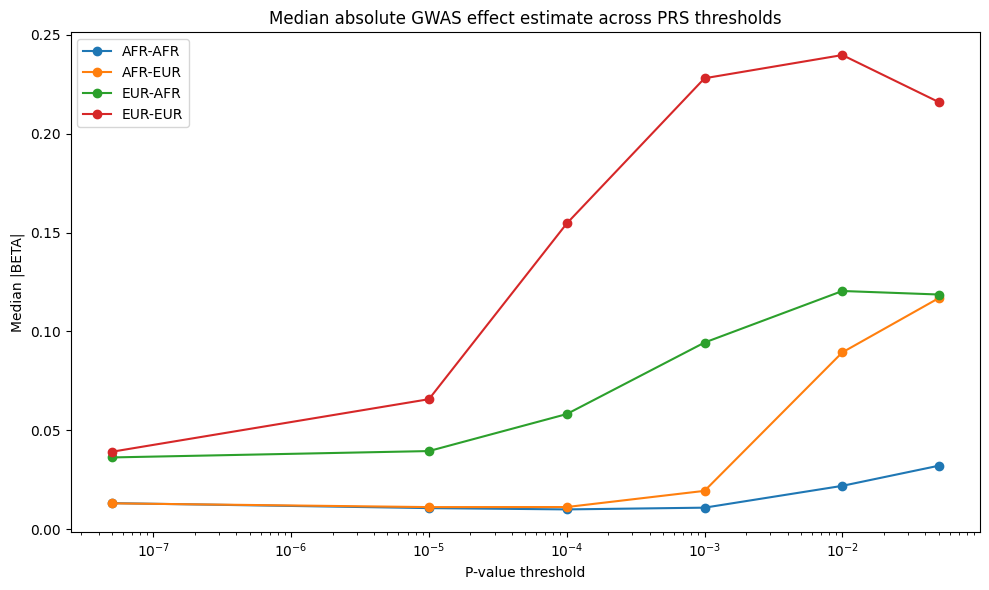

In [ ]:
plt.figure(figsize=(10, 6))

for pipeline in weight_data:

    median_abs_beta = []

    for threshold in THRESHOLDS:

        df = weight_data[pipeline][threshold]

        median_abs_beta.append(
            df["BETA"].abs().median()
        )

    plt.plot(
        list(THRESHOLDS.values()),
        median_abs_beta,
        marker="o",
        label=pipeline
    )

plt.xscale("log")
plt.xlabel("P-value threshold")
plt.ylabel("Median |BETA|")
plt.title("Median absolute GWAS effect estimate across PRS thresholds")
plt.legend()
plt.tight_layout()
plt.show()

## EAF comparison

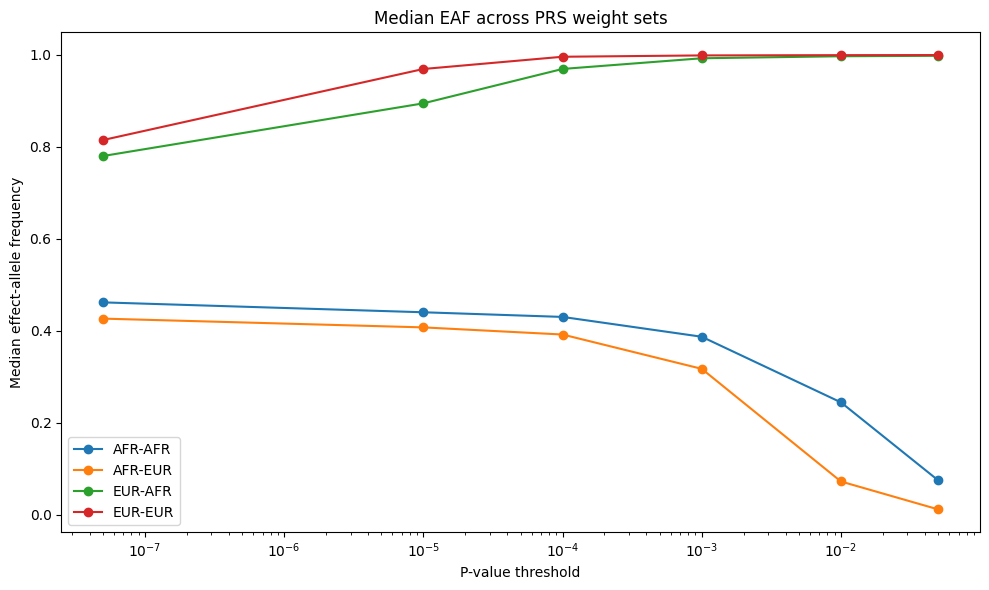

In [ ]:
plt.figure(figsize=(10, 6))

for pipeline in weight_data:

    median_eaf = []

    for threshold in THRESHOLDS:

        df = weight_data[pipeline][threshold]

        median_eaf.append(
            df["EAF"].median()
        )

    plt.plot(
        list(THRESHOLDS.values()),
        median_eaf,
        marker="o",
        label=pipeline
    )

plt.xscale("log")
plt.xlabel("P-value threshold")
plt.ylabel("Median effect-allele frequency")
plt.title("Median EAF across PRS weight sets")
plt.legend()
plt.tight_layout()
plt.show()

## Final same-GWAS comparison

In [ ]:
afr_weight_comparison = weight_summary[
    weight_summary["Pipeline"].isin(
        ["AFR-AFR", "AFR-EUR"]
    )
].pivot(
    index="Threshold",
    columns="Pipeline",
    values=[
        "Weighted_SNPs",
        "Mean_abs_BETA",
        "Median_abs_BETA",
        "Median_EAF"
    ]
)

display(afr_weight_comparison)

Weighted_SNPs           Mean_abs_BETA           Median_abs_BETA  \
Pipeline        AFR-AFR   AFR-EUR       AFR-AFR   AFR-EUR         AFR-AFR   
Threshold                                                                   
P0.0001          7666.0    3302.0      0.019861  0.038640        0.010097   
P0.001          19691.0   11288.0      0.034967  0.078009        0.010975   
P0.01           90187.0   74325.0      0.067797  0.133066        0.022005   
P0.05          357804.0  358128.0      0.087556  0.158121        0.032159   
P1e-05           4305.0    1636.0      0.016892  0.022264        0.010758   
P5e-08           1710.0     633.0      0.019870  0.017952        0.013268   

                    Median_EAF           
Pipeline    AFR-EUR    AFR-AFR  AFR-EUR  
Threshold                                
P0.0001    0.011292    0.42990  0.39165  
P0.001     0.019471    0.38680  0.31705  
P0.01      0.089439    0.24420  0.07223  
P0.05      0.116806    0.07462  0.01157  
P1e-05     0.011262    0.44000  0.40715  
P5e-08     0.013163    0.46150  0.42620

In [ ]:
eur_weight_comparison = weight_summary[
    weight_summary["Pipeline"].isin(
        ["EUR-AFR", "EUR-EUR"]
    )
].pivot(
    index="Threshold",
    columns="Pipeline",
    values=[
        "Weighted_SNPs",
        "Mean_abs_BETA",
        "Median_abs_BETA",
        "Median_EAF"
    ]
)

display(eur_weight_comparison)

Weighted_SNPs           Mean_abs_BETA           Median_abs_BETA  \
Pipeline        EUR-AFR   EUR-EUR       EUR-AFR   EUR-EUR         EUR-AFR   
Threshold                                                                   
P0.0001         37511.0   25465.0      0.143728  0.253381        0.058269   
P0.001         107335.0   83925.0      0.172999  0.278008        0.094401   
P0.01          364262.0  319256.0      0.178537  0.269150        0.120446   
P0.05          920240.0  842495.0      0.163956  0.240813        0.118672   
P1e-05          16558.0    9216.0      0.106479  0.191669        0.039573   
P5e-08           4944.0    2063.0      0.063639  0.081519        0.036353   

                    Median_EAF          
Pipeline    EUR-EUR    EUR-AFR EUR-EUR  
Threshold                               
P0.0001    0.154551    0.96880  0.9953  
P0.001     0.227932    0.99200  0.9982  
P0.01      0.239654    0.99640  0.9988  
P0.05      0.215918    0.99740  0.9990  
P1e-05     0.065788    0.89405  0.9687  
P5e-08     0.039221    0.77960  0.8143

## Saving outputs

In [ ]:
COMPARISON_DIR_07 = Path(
    "/content/drive/MyDrive/"
    "PRS_T2D_comparison/"
    "PRS_Weight_Comparison"
)

COMPARISON_DIR_07.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR_07 = (
    COMPARISON_DIR_07 / "figures"
)

FIGURE_DIR_07.mkdir(
    parents=True,
    exist_ok=True
)

print(COMPARISON_DIR_07)

/content/drive/MyDrive/PRS_T2D_comparison/PRS_Weight_Comparison


In [ ]:
weight_summary.to_csv(
    COMPARISON_DIR_07 / "weight_summary.tsv",
    sep="\t",
    index=False
)

weight_duplicate_check.to_csv(
    COMPARISON_DIR_07 / "weight_duplicate_check.tsv",
    sep="\t",
    index=False
)

index_weight_check.to_csv(
    COMPARISON_DIR_07 / "index_weight_count_check.tsv",
    sep="\t",
    index=False
)

afr_weight_overlap.to_csv(
    COMPARISON_DIR_07 / "AFR_GWAS_weight_overlap.tsv",
    sep="\t",
    index=False
)

eur_weight_overlap.to_csv(
    COMPARISON_DIR_07 / "EUR_GWAS_weight_overlap.tsv",
    sep="\t",
    index=False
)

effect_direction.to_csv(
    COMPARISON_DIR_07 / "effect_direction_summary.tsv",
    sep="\t",
    index=False
)

print("Notebook 07 tables saved.")

Notebook 07 tables saved.
